# Analyse exploratoire — Météo spatiale

**Périmètre** : éruptions solaires (DONKI, NASA) et détections instrumentales (NOAA SWPC).

**Objectif** : comprendre la structure des données pour choisir une cible de Machine
Learning défendable, et documenter les limites à mentionner en restitution.

**Source** : les marts du dataset `dbt_ouma`, construits par dbt. On part de la couche
Gold, destinée à l'analyse, et non des tables brutes.

**Données arrêtées au 25 septembre 2026.** Les sources sont mises à jour en continu :
les chiffres cités dans les interprétations correspondent à cette exécution.

> Chaque section se termine par une interprétation écrite des résultats obtenus.

## 1. Préparation

```bash
pip install pandas matplotlib seaborn db-dtypes
```

`db-dtypes` convertit les types BigQuery en types pandas.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery

load_dotenv()

PROJECT_ID = os.getenv("GCP_PROJECT_ID")
DATASET = "dbt_ouma"

client = bigquery.Client(project=PROJECT_ID)

# Couleurs du notebook.
# BLEUS va du clair au foncé : les classes d'éruption sont ordonnées par
# intensité (A < B < C < M < X), la couleur doit le montrer.
BLEU = "#2C6E9B"
BLEUS = ["#CBDDEB", "#9DC0DA", "#6BA3C7", "#3E7FAE", "#1F5582"]
ALERTE = "#B4453C"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"Connecté au projet {PROJECT_ID}, dataset {DATASET}.")

Connecté au projet votre-projet-gcp, dataset dbt_ouma.


## 2. Chargement des données

In [2]:
def charger(table):
    """Charge une table du dataset dans un DataFrame."""
    return client.query(f"SELECT * FROM `{PROJECT_ID}.{DATASET}.{table}`").to_dataframe()


flares = charger("fct_solar_flares")
noaa = charger("fct_noaa_events")
regions = charger("dim_active_regions")
types = charger("dim_event_types")

# BigQuery renvoie les entiers en type Int64, que matplotlib ne sait pas tracer.
flares["duree_minutes"] = flares["duree_minutes"].astype(float)
flares["active_region_number"] = flares["active_region_number"].astype(float)

# L'année sert à l'analyse du cycle solaire.
flares["event_start_time"] = pd.to_datetime(flares["event_start_time"])
flares["annee"] = flares["event_start_time"].dt.year

print(f"Éruptions DONKI : {len(flares)} lignes")
print(f"Détections NOAA : {len(noaa)} lignes")
print(f"Régions actives : {len(regions)} lignes")
print(f"Types NOAA      : {len(types)} lignes")
print(f"Période couverte : {flares['annee'].min()} - {flares['annee'].max()}")

/Users/oumaimaelazhari/projets/Projet-Certification-NASA/Projet-Certification-NASA/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2130: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
/Users/oumaimaelazhari/projets/Projet-Certification-NASA/Projet-Certification-NASA/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2130: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
/Users/oumaimaelazhari/projets/Projet-Certification-NASA/Projet-Certification-NASA/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2130: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(
/Users/oumaimaelazhari/projets/Projet-Certification-NASA/Projet-Certification-NASA/venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2130: UserWarning: BigQuery Storage module not found, fetch data w

Éruptions DONKI : 3065 lignes
Détections NOAA : 1366 lignes
Régions actives : 649 lignes
Types NOAA      : 9 lignes
Période couverte : 2015 - 2026


## 3. Qualité des données

In [3]:
flares.info()

<class 'pandas.DataFrame'>
RangeIndex: 3065 entries, 0 to 3064
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   solar_flare_id         3065 non-null   str                
 1   date_key               3065 non-null   dbdate             
 2   active_region_number   2954 non-null   float64            
 3   event_start_time       3065 non-null   datetime64[us, UTC]
 4   event_peak_time        3065 non-null   datetime64[us, UTC]
 5   event_end_time         3024 non-null   datetime64[us, UTC]
 6   duree_minutes          3024 non-null   float64            
 7   flare_class            3065 non-null   str                
 8   classe_lettre          3065 non-null   str                
 9   classe_multiplicateur  3065 non-null   float64            
 10  declenche_cme          3065 non-null   boolean            
 11  solar_region_location  3065 non-null   str                
 12  nas

In [4]:
manquantes = flares.isnull().sum()
manquantes = manquantes[manquantes > 0]
pourcentage = (manquantes / len(flares) * 100).round(1)

print("Valeurs manquantes :")
for colonne in manquantes.index:
    print(f"  {colonne} : {manquantes[colonne]} lignes ({pourcentage[colonne]} %)")

Valeurs manquantes :
  active_region_number : 111 lignes (3.6 %)
  event_end_time : 41 lignes (1.3 %)
  duree_minutes : 41 lignes (1.3 %)


In [5]:
sans_fin = flares[flares["event_end_time"].isna()]

print(f"{len(sans_fin)} éruptions sans heure de fin")
print("\nRépartition par classe :")
print(sans_fin["classe_lettre"].value_counts().to_string())
print("\nÀ comparer au catalogue entier :")
print(flares["classe_lettre"].value_counts(normalize=True).round(3).to_string())

41 éruptions sans heure de fin

Répartition par classe :
classe_lettre
C    25
B    13
M     2
A     1

À comparer au catalogue entier :
classe_lettre
M    0.763
C    0.185
X    0.037
B    0.014
A    0.000


**Interprétation**

Trois colonnes présentent des valeurs manquantes, toutes dans une proportion inférieure à 4 %. `event_end_time` et `duree_minutes` sont absentes sur exactement les mêmes 41 lignes. Comme la durée est calculée à partir de l’heure de fin, ces deux valeurs manquantes correspondent à un même problème de données et non à deux problèmes distincts.

Le résultat est particulièrement intéressant pour `event_end_time` : il contredit l’hypothèse initiale selon laquelle les éruptions les plus fortes seraient davantage concernées. Parmi les 41 éruptions sans heure de fin, 38 sont de classe B ou C, soit 93 %, alors que ces classes représentent seulement 20 % du catalogue. À l’inverse, seules 2 éruptions sont de classe M et aucune de classe X n'est concernée.

Cette répartition suggère que les valeurs manquantes ne sont pas distribuées aléatoirement. Une explication plausible est que, pour les éruptions faibles, la phase de décroissance devient difficile à distinguer du bruit de fond du rayonnement X, ce qui rend l'heure de fin moins facilement identifiable. À l'inverse, le signal d'une éruption X étant beaucoup plus marqué, son retour au niveau de référence est généralement plus facilement identifiable.

Cette observation a une conséquence directe sur l'imputation de `duree_minutes`. Une médiane calculée sur l'ensemble du catalogue serait fortement influencée par les éruptions de classe M, qui représentent 76,3 % des observations. Elle risquerait donc de surestimer la durée des éruptions B et C auxquelles elle serait principalement appliquée. Il serait plus pertinent d'utiliser une médiane calculée par classe d'éruption, afin de tenir compte des différences de durée entre les niveaux d'intensité.

Cette hypothèse d'une imputation par classe sera réexaminée en section 6, une fois les durées nettoyées et les médianes comparées entre classes.

## 4. Distribution des classes d'éruption

L'échelle est **logarithmique** : chaque lettre vaut dix fois la précédente. Une M1 est
dix fois plus forte qu'une C1, une X1 cent fois. Le chiffre qui suit est un multiplicateur
— une M5 est cinq fois plus forte qu'une M1, et seulement deux fois moins forte qu'une X1.

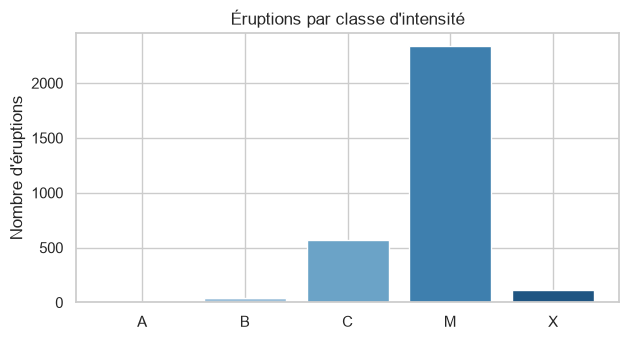

  A : 1 éruptions (0.0 %)
  B : 44 éruptions (1.4 %)
  C : 567 éruptions (18.5 %)
  M : 2340 éruptions (76.3 %)
  X : 113 éruptions (3.7 %)


In [6]:
distribution = flares["classe_lettre"].value_counts().sort_index()

plt.figure(figsize=(7, 3.5))
plt.bar(distribution.index, distribution.values, color=BLEUS)
plt.title("Éruptions par classe d'intensité")
plt.ylabel("Nombre d'éruptions")
plt.show()

for classe in distribution.index:
    nombre = distribution[classe]
    part = nombre / len(flares) * 100
    print(f"  {classe} : {nombre} éruptions ({part:.1f} %)")

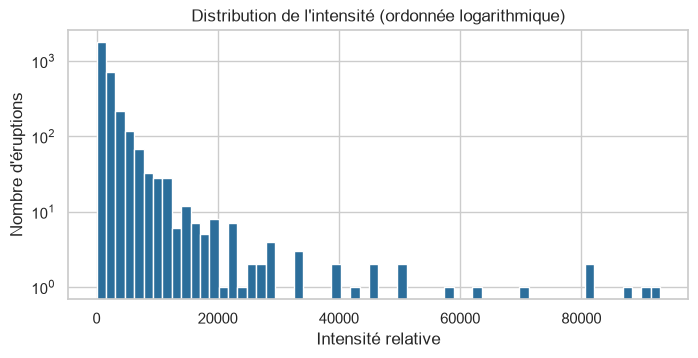

count     3065.0
mean      2634.0
std       5431.0
min          9.0
25%       1000.0
50%       1400.0
75%       2400.0
max      93000.0

Les dix éruptions les plus fortes :
             solar_flare_id flare_class  active_region_number  duree_minutes
2017-09-06T11:53:00-FLR-001        X9.3               12673.0           17.0
2024-10-03T12:08:00-FLR-001        X9.0               13842.0           19.0
2024-05-14T16:46:00-FLR-001        X8.7               13664.0           16.0
2017-09-10T15:35:00-FLR-001        X8.2               12673.0           56.0
2026-02-01T23:44:00-FLR-001        X8.1               14366.0           20.0
2024-10-01T21:58:00-FLR-001        X7.1               13842.0           31.0
2024-02-22T22:08:00-FLR-001        X6.3               13590.0           35.0
2024-05-11T01:10:00-FLR-001        X5.8               13664.0           29.0
2025-11-11T09:49:00-FLR-001        X5.1               14274.0           28.0
2023-12-31T21:40:00-FLR-001        X5.0               135

In [7]:
# La lettre donne l'ordre de grandeur, le multiplicateur affine à l'intérieur.
PUISSANCE = {"A": 1, "B": 10, "C": 100, "M": 1000, "X": 10000}

flares["intensite"] = flares["classe_lettre"].map(PUISSANCE) * flares["classe_multiplicateur"]

plt.figure(figsize=(8, 3.5))
plt.hist(flares["intensite"].dropna(), bins=60, color=BLEU, log=True)
plt.title("Distribution de l'intensité (ordonnée logarithmique)")
plt.xlabel("Intensité relative")
plt.ylabel("Nombre d'éruptions")
plt.show()

print(flares["intensite"].describe().round(0).to_string())

print("\nLes dix éruptions les plus fortes :")
print(flares.nlargest(10, "intensite")[
    ["solar_flare_id", "flare_class", "active_region_number", "duree_minutes"]
].to_string(index=False))

**Interprétation**

L'intensité des éruptions est très fortement asymétrique. La médiane est de 1 400, contre une moyenne de 2 634 et un maximum de 93 000. La moyenne étant nettement supérieure à la médiane, quelques éruptions extrêmement fortes tirent la distribution vers le haut.

Les 50 % centraux des observations se situent entre 1 000 et 2 400, soit entre M1.0 et M2.4. Le fait que le premier quartile soit exactement égal à 1 000, soit M1.0, renforce également l'hypothèse d'un seuil de catalogage autour de cette intensité, déjà observée dans l'analyse de la distribution des classes.

Les valeurs extrêmes ne doivent pas être considérées comme des anomalies à supprimer : elles correspondent à de véritables éruptions de forte intensité. Les dix éruptions les plus fortes du catalogue sont toutes de classe X, et la plus forte atteint X9.3, soit une intensité relative de 93 000.

Cette forte asymétrie rend pertinente l'utilisation d'une transformation logarithmique de l'intensité pour le Machine Learning. Elle est utile en régression, car elle limite l'influence disproportionnée des valeurs extrêmes, mais également en classification lorsque l'intensité est utilisée comme variable explicative. Sur une échelle brute, une différence de 1 000 unités entre 1 000 et 2 000 serait traitée comme équivalente à une différence de 1 000 unités entre 90 000 et 91 000, alors que ces variations n'ont pas la même signification relative. La transformation logarithmique permet donc de mieux représenter les écarts proportionnels entre les intensités.

La médiane est par ailleurs plus représentative que la moyenne pour décrire une éruption typique, car elle est beaucoup moins sensible aux quelques événements extrêmement intenses.


## 5. Analyse temporelle — le cycle solaire

Le Soleil suit un cycle d'environ 11 ans. La collecte historique couvre 2015-2026, soit
deux maxima et un minimum : c'est précisément ce qui justifiait le backfill.

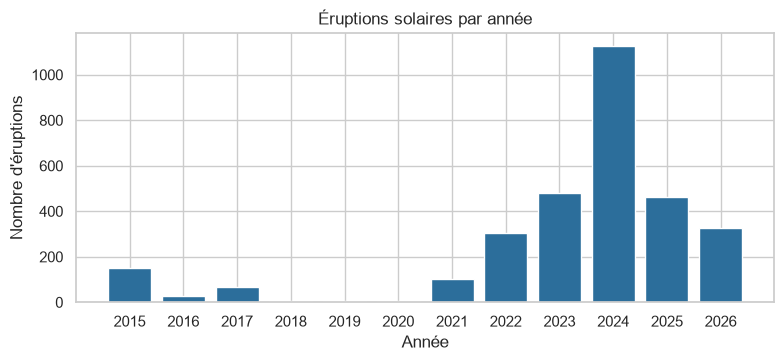

annee
2015     152
2016      27
2017      67
2018       4
2019       7
2020       7
2021     101
2022     304
2023     479
2024    1128
2025     464
2026     325

Maximum : 2024 (1128 éruptions)
Minimum : 2018 (4 éruptions)
Amplitude : facteur 282


In [8]:
par_annee = flares.groupby("annee").size()

plt.figure(figsize=(9, 3.5))
plt.bar(par_annee.index, par_annee.values, color=BLEU)
plt.title("Éruptions solaires par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'éruptions")
plt.xticks(par_annee.index)
plt.show()

print(par_annee.to_string())

print(f"\nMaximum : {par_annee.idxmax()} ({par_annee.max()} éruptions)")
print(f"Minimum : {par_annee.idxmin()} ({par_annee.min()} éruptions)")
print(f"Amplitude : facteur {par_annee.max() / par_annee.min():.0f}")

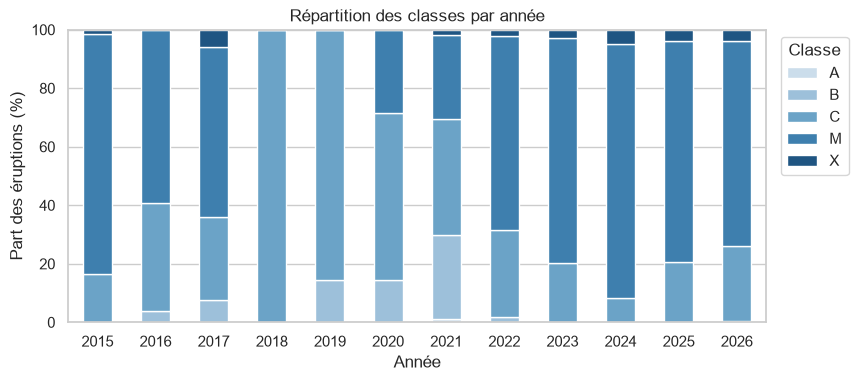

classe_lettre    A     B      C     M    X
annee                                     
2015           0.0   0.0   16.4  82.2  1.3
2016           0.0   3.7   37.0  59.3  0.0
2017           0.0   7.5   28.4  58.2  6.0
2018           0.0   0.0  100.0   0.0  0.0
2019           0.0  14.3   85.7   0.0  0.0
2020           0.0  14.3   57.1  28.6  0.0
2021           1.0  28.7   39.6  28.7  2.0
2022           0.0   1.6   29.9  66.1  2.3
2023           0.0   0.2   20.0  77.0  2.7
2024           0.0   0.0    8.2  87.1  4.8
2025           0.0   0.0   20.7  75.4  3.9
2026           0.0   0.3   25.8  69.8  4.0

Intensité médiane par année :
annee
2015    1350.0
2016    1000.0
2017    1200.0
2018     240.0
2019     500.0
2020     400.0
2021     380.0
2022    1200.0
2023    1300.0
2024    1500.0
2025    1300.0
2026    1400.0

Corrélation nombre / intensité : 0.66


In [9]:
# Le cycle porte-t-il aussi sur l'intensité, ou seulement sur la fréquence ?
croisement = pd.crosstab(flares["annee"], flares["classe_lettre"], normalize="index") * 100

croisement.plot(kind="bar", stacked=True, color=BLEUS, figsize=(9, 3.8),
                edgecolor="white", linewidth=1)
plt.title("Répartition des classes par année")
plt.xlabel("Année")
plt.ylabel("Part des éruptions (%)")
plt.legend(title="Classe", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
plt.show()

print(croisement.round(1).to_string())

intensite_annuelle = flares.groupby("annee")["intensite"].median()
print("\nIntensité médiane par année :")
print(intensite_annuelle.round(0).to_string())
print(f"\nCorrélation nombre / intensité : {par_annee.corr(intensite_annuelle):.2f}")

In [10]:
resume = pd.DataFrame({
    "nb_eruptions": par_annee,
    "intensite_mediane": intensite_annuelle.round(0),
})
print(resume.to_string())

       nb_eruptions  intensite_mediane
annee                                 
2015            152             1350.0
2016             27             1000.0
2017             67             1200.0
2018              4              240.0
2019              7              500.0
2020              7              400.0
2021            101              380.0
2022            304             1200.0
2023            479             1300.0
2024           1128             1500.0
2025            464             1300.0
2026            325             1400.0


**Interprétation**

Le cycle solaire est nettement visible sur le nombre d'éruptions cataloguées : seulement 4 événements sont recensés en 2018, contre 1 128 en 2024, soit un facteur 282. Le minimum observé entre 2018 et 2020 et le pic de 2024 correspondent à la transition entre les cycles solaires 24 et 25.

La corrélation de 0,66 entre le nombre annuel d'éruptions et leur intensité médiane ne doit cependant pas être interprétée comme la preuve d'un effet du cycle solaire sur l'intensité des éruptions individuelles.

Plusieurs éléments incitent à la prudence. Les années 2018 à 2020 reposent sur seulement 4 à 7 éruptions, ce qui rend leur médiane peu robuste. À l'inverse, les années les plus actives présentent des médianes relativement stables : 1 200, 1 300, 1 500, 1 300 et 1 400 entre 2022 et 2026, alors que le nombre d'événements varie fortement. Cette stabilité est cohérente avec le seuil de catalogage identifié précédemment : lorsque le catalogue contient suffisamment d'éruptions de classe M, sa médiane se situe autour de M1.0-M1.5.

L'année 2021 constitue également un cas intéressant. Avec 101 éruptions et une médiane de 380, elle montre que la reprise de l'activité en fréquence ne s'accompagne pas nécessairement d'une intensité médiane élevée. Le catalogue contient alors encore 28,7 % d'éruptions de classe B.

La variation de l'intensité médiane semble donc refléter en partie la composition du catalogue et son niveau de représentation des faibles éruptions selon les périodes. Sur cette source, le cycle solaire est clairement mesurable à travers la fréquence des éruptions cataloguées. En revanche, les données disponibles ne permettent pas d'établir que le cycle entraîne une augmentation ou une diminution systématique de l'intensité des éruptions individuelles.


## 6. Durée des éruptions

Les durées brutes contiennent des valeurs incohérentes qui rendent toute statistique
inexploitable. On les identifie d'abord, on les neutralise, puis on analyse.

In [11]:
negatives = (flares["duree_minutes"] < 0).sum()
longues = (flares["duree_minutes"] > 600).sum()

print(f"{negatives} durée(s) négative(s)")
print(f"{longues} durée(s) au-delà de 10 heures")

print(f"Écart-type avant nettoyage : {flares['duree_minutes'].std():.0f} minutes")

4 durée(s) négative(s)
4 durée(s) au-delà de 10 heures
Écart-type avant nettoyage : 19389 minutes


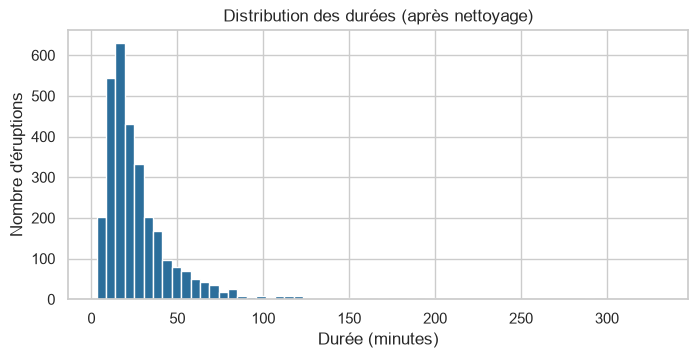

count    3016.0
mean       28.0
std        27.0
min         3.0
25%        14.0
50%        21.0
75%        33.0
max       331.0

49 valeurs manquantes au total


In [12]:
# Une éruption solaire dure de quelques minutes à quelques heures. Au-delà de
# 10 heures ou en dessous de zéro, c'est une incohérence de saisie et non un
# événement réel : on la traite comme une valeur manquante.
flares.loc[(flares["duree_minutes"] < 0) | (flares["duree_minutes"] > 600),
           "duree_minutes"] = None

plt.figure(figsize=(8, 3.5))
plt.hist(flares["duree_minutes"].dropna(), bins=60, color=BLEU)
plt.title("Distribution des durées (après nettoyage)")
plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre d'éruptions")
plt.show()

print(flares["duree_minutes"].describe().round(0).to_string())
print(f"\n{flares['duree_minutes'].isna().sum()} valeurs manquantes au total")

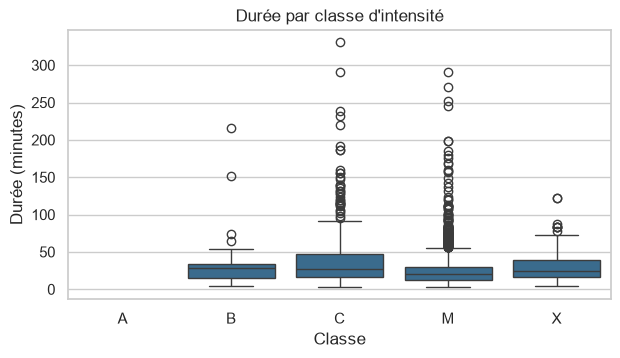

Durée médiane par classe (minutes) :
classe_lettre
A     NaN
B    28.0
C    27.0
M    20.0
X    25.0


In [13]:
plt.figure(figsize=(7, 3.5))
sns.boxplot(data=flares, x="classe_lettre", y="duree_minutes",
            order=["A", "B", "C", "M", "X"], color=BLEU)
plt.title("Durée par classe d'intensité")
plt.xlabel("Classe")
plt.ylabel("Durée (minutes)")
plt.show()

print("Durée médiane par classe (minutes) :")
print(flares.groupby("classe_lettre")["duree_minutes"].median().round(0).to_string())

**Interprétation**

Avant nettoyage, 8 durées sont incohérentes parmi les 3 024 durées calculées : 4 sont négatives et 4 dépassent 600 minutes, soit 10 heures. Ces valeurs ne sont pas exploitables et sont donc traitées comme des valeurs manquantes plutôt que conservées dans l'analyse.

L'impact de ces quelques valeurs sur les statistiques est particulièrement important : l'écart-type passe de 19 389 minutes avant nettoyage à seulement 27 minutes après nettoyage. Ainsi, seulement 8 lignes sur plus de 3 000 faisaient varier l'écart-type d'un facteur supérieur à 700. Cela confirme que ces valeurs extrêmes ne peuvent pas être considérées comme de simples observations atypiques et qu'elles doivent être neutralisées avant d'interpréter la distribution.

Le seuil de 600 minutes peut sembler arbitraire, mais les données permettent de le justifier : après nettoyage, la durée maximale observée est de 331 minutes. Il n'existe donc aucune éruption entre 331 et 600 minutes. La coupure se situe ainsi dans un intervalle sans observation et n'écarte aucun cas ambigu.

Après nettoyage, 3 016 durées restent disponibles. La distribution est asymétrique : la durée moyenne est de 28 minutes, contre une médiane de 21 minutes. La moitié des éruptions durent entre 14 et 33 minutes, tandis que la durée maximale atteint 331 minutes. La moyenne supérieure à la médiane s'explique donc par la présence de quelques éruptions particulièrement longues qui tirent la moyenne vers le haut.

La comparaison par classe montre que la durée ne suit pas une progression simple avec l'intensité. Les durées médianes sont de 28 minutes pour B, 27 minutes pour C, 20 minutes pour M et 25 minutes pour X. Les écarts restent relativement faibles, avec seulement 8 minutes entre la médiane la plus élevée et la plus faible. On ne peut donc pas conclure que les éruptions plus intenses durent systématiquement plus longtemps.

La classe A ne dispose d'aucune durée exploitable. Avec une seule observation dans le catalogue, elle ne permet pas de tirer de conclusion sur la durée.

Pour une étape de Machine Learning, l'imputation par la médiane globale est donc acceptable : les médianes par classe s'échelonnent de 20 à 28 minutes, un écart trop faible pour justifier un traitement différencié. La médiane globale de 21 minutes constitue ainsi une valeur robuste pour remplacer les durées manquantes.


## 7. Les régions actives

Une région active est une zone magnétiquement perturbée du Soleil. Certaines produisent
une éruption isolée, d'autres des dizaines.

In [14]:
par_region = flares.groupby("active_region_number").agg(
    nb_eruptions=("solar_flare_id", "count"),
    intensite_max=("intensite", "max"),
)

print(f"{len(par_region)} régions actives distinctes")
print(f"Médiane : {par_region['nb_eruptions'].median():.0f} éruption(s) par région")
print(f"Maximum : {par_region['nb_eruptions'].max():.0f} éruptions")

print("\nLes 10 régions les plus actives :")
print(par_region.sort_values("nb_eruptions", ascending=False).head(10).round(0).to_string())

633 régions actives distinctes
Médiane : 2 éruption(s) par région
Maximum : 90 éruptions

Les 10 régions les plus actives :
                      nb_eruptions  intensite_max
active_region_number                             
13664.0                         90        87000.0
14366.0                         85        81000.0
13615.0                         51        11000.0
14479.0                         47        11000.0
13663.0                         42        45000.0
13842.0                         33        90000.0
13697.0                         33        28000.0
12673.0                         32        93000.0
13165.0                         29         6300.0
13981.0                         29         8800.0


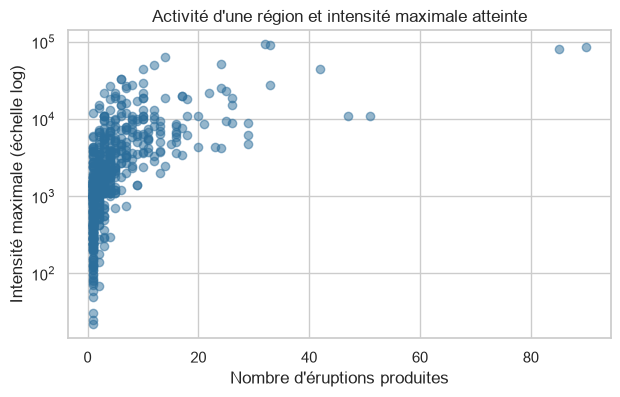

Corrélation : 0.69


In [15]:
plt.figure(figsize=(7, 4))
plt.scatter(par_region["nb_eruptions"], par_region["intensite_max"],
            alpha=0.5, color=BLEU)
plt.yscale("log")
plt.title("Activité d'une région et intensité maximale atteinte")
plt.xlabel("Nombre d'éruptions produites")
plt.ylabel("Intensité maximale (échelle log)")
plt.show()

print(f"Corrélation : {par_region['nb_eruptions'].corr(par_region['intensite_max']):.2f}")

**Interprétation**

Le catalogue contient 633 régions actives distinctes. La majorité est peu active : la médiane est de seulement 2 éruptions par région. À l’inverse, certaines régions concentrent un grand nombre d’événements, avec un maximum de 90 éruptions pour la région 13664. La distribution de l’activité entre les régions est donc très déséquilibrée : quelques régions produisent une part importante des éruptions cataloguées.

Le coefficient de corrélation entre le nombre d’éruptions et l’intensité maximale est de 0,69. Cette relation doit toutefois être interprétée avec prudence, car elle est en partie mécanique : plus une région produit d’éruptions, plus elle dispose d’occasions de produire une éruption très intense. Le maximum observé a donc naturellement tendance à augmenter avec le nombre d'observations.

La dispersion du graphique montre également que le nombre d’éruptions ne suffit pas à expliquer l’intensité maximale. Par exemple, la région 13842 produit seulement 33 éruptions mais atteint une intensité maximale de 90 000, tandis que la région 13664, pourtant la plus active avec 90 éruptions, atteint au maximum 87 000. La région la plus active du catalogue n’est donc pas celle qui atteint l’intensité maximale la plus élevée.

La région 12673, avec 32 éruptions, atteint quant à elle 93 000, correspondant à l’éruption X9.3 identifiée précédemment comme la plus intense du catalogue.

Le nombre d’éruptions par région peut donc constituer une variable explicative intéressante pour le Machine Learning, mais sa corrélation avec l’intensité maximale ne doit pas être lue comme une relation causale.


## 8. Le lien vers les éjections de masse coronale

C'est le cœur de la problématique. Une éruption envoie un rayonnement X qui atteint la
Terre en 8 minutes — trop tard pour agir. Le danger pour les réseaux électriques vient
du **CME**, l'éjection de masse coronale, qui met 1 à 3 jours à nous atteindre et provoque
les tempêtes géomagnétiques.

Toutes les éruptions n'en produisent pas. C'est cette distinction qui définit le risque réel.

In [16]:
taux_global = flares["declenche_cme"].mean() * 100

print(f"{len(flares)} éruptions analysées")
print(f"{flares['declenche_cme'].sum()} associées à un CME ({taux_global:.1f} %)")

3065 éruptions analysées
1214 associées à un CME (39.6 %)


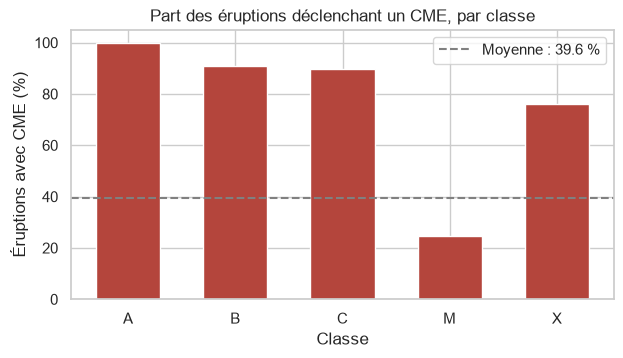

               nb_eruptions  taux_cme_%
classe_lettre                          
A                         1       100.0
B                        44        90.9
C                       567        89.6
M                      2340        24.7
X                       113        76.1


In [17]:
taux = flares.groupby("classe_lettre")["declenche_cme"].agg(["count", "mean"])
taux["mean"] = (taux["mean"] * 100).round(1)
taux.columns = ["nb_eruptions", "taux_cme_%"]

plt.figure(figsize=(7, 3.5))
plt.bar(taux.index, taux["taux_cme_%"], color=ALERTE, width=0.6)
plt.axhline(taux_global, color="grey", linestyle="--", label=f"Moyenne : {taux_global:.1f} %")
plt.title("Part des éruptions déclenchant un CME, par classe")
plt.xlabel("Classe")
plt.ylabel("Éruptions avec CME (%)")
plt.legend()
plt.show()

print(taux.to_string())

**Interprétation**

Sur les 3 065 éruptions analysées, 1 214 sont associées à un CME, soit un taux global de 39,6 %. Ce taux global doit toutefois être interprété avec prudence, car la composition du catalogue est fortement déséquilibrée selon les classes d'intensité : 2 340 éruptions sont de classe M, contre 567 de classe C et seulement 113 de classe X.

Les taux observés pour les classes B et C, respectivement 90,9 % et 89,6 %, ne peuvent donc pas être interprétés comme une probabilité physique qu'une faible éruption déclenche un CME. Ils sont cohérents avec le biais de catalogage déjà identifié : les éruptions faibles ne sont pas représentées de manière exhaustive dans DONKI. Or, physiquement, le Soleil produit environ dix fois plus d'éruptions C que M. 

Un catalogue exhaustif compterait donc plusieurs milliers de C pour quelques centaines de M : l'inversion observée confirme que le catalogage n'est pas systématique en dessous de M1.0. Une partie des éruptions B et C présentes dans le catalogue peut ainsi avoir été retenue parce qu'elles étaient associées à un événement particulier, notamment un CME. Leur taux de CME est donc fortement biaisé par le processus de sélection du catalogue.

Pour analyser la relation entre intensité et CME dans un régime de catalogage plus homogène, il est donc plus pertinent de se concentrer sur les classes M et X. Sur ces 2 453 éruptions, le taux d'association avec un CME est de 27,1 %. Surtout, le taux passe de 24,7 % pour les M à 76,1 % pour les X. Dans ce sous-ensemble, la relation observée est donc croissante : les éruptions les plus intenses sont beaucoup plus fréquemment associées à un CME.

La classe X doit néanmoins être interprétée avec prudence, car elle ne représente que 113 observations. La classe A, avec une seule éruption, n'est quant à elle pas exploitable pour tirer une conclusion statistique.

Cette analyse conduit donc à réviser la première lecture du graphique : l'intensité ne peut pas être interprétée à partir de l'ensemble B–X sans tenir compte du biais de sélection. Sur le régime M–X, qui constitue le sous-ensemble le plus homogène du catalogue, l'intensité apparaît en revanche comme une variable potentiellement informative pour prédire l'association avec un CME.

Pour le Machine Learning, je retiens donc M et X comme population d'analyse, plutôt que le taux global de 39,6 %. La cible reste une classification binaire, mais elle doit être construite sur ce périmètre homogène afin de limiter l'effet du biais de catalogage.

Enfin, il faut éviter toute fuite de données (data leakage) : linked_events sert à construire la cible « présence d'un CME » et ne doit donc pas être utilisé comme variable explicative du modèle.

## 9. Les détections NOAA

Grain plus fin que DONKI : une même éruption peut produire plusieurs détections par des
instruments différents. La fenêtre est limitée à une trentaine de jours — c'est ce que le
flux expose, pas un choix de collecte.

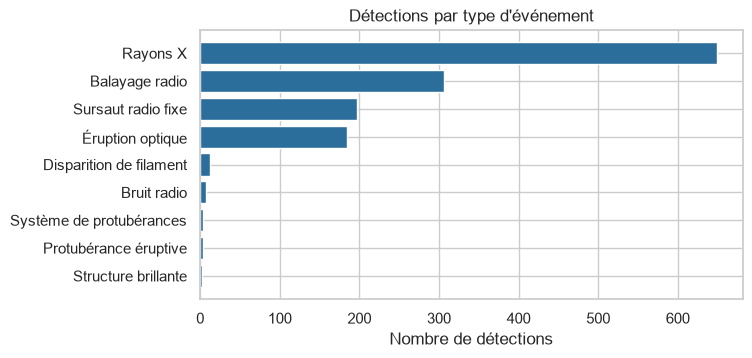

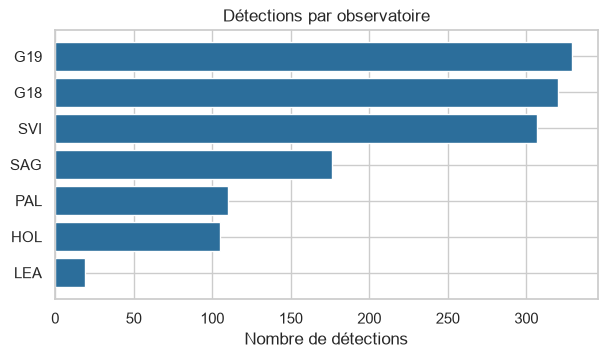

libelle
Rayons X                    649
Balayage radio              306
Sursaut radio fixe          197
Éruption optique            185
Disparition de filament      12
Bruit radio                   7
Protubérance éruptive         4
Système de protubérances      4
Structure brillante           2

7 observatoires distincts


In [18]:
noaa_types = noaa.merge(types, on="event_type", how="left")
par_type = noaa_types["libelle"].value_counts().sort_values()

plt.figure(figsize=(7, 3.5))
plt.barh(par_type.index, par_type.values, color=BLEU)
plt.title("Détections par type d'événement")
plt.xlabel("Nombre de détections")
plt.show()

observatoires = noaa["observatory"].value_counts().sort_values()

plt.figure(figsize=(7, 3.5))
plt.barh(observatoires.index, observatoires.values, color=BLEU)
plt.title("Détections par observatoire")
plt.xlabel("Nombre de détections")
plt.show()

print(par_type.sort_values(ascending=False).to_string())
print(f"\n{noaa['observatory'].nunique()} observatoires distincts")

**Interprétation :**


Les détections NOAA sont très fortement concentrées sur quelques types d'événements. Les quatre catégories principales sont les rayons X avec 649 détections, le balayage radio avec 306, le sursaut radio fixe avec 197 et l'éruption optique avec 185. À elles seules, ces quatre catégories regroupent 1 337 détections sur 1 366, soit environ 98 % du total, tandis que les autres types comptent moins d'une quinzaine de détections chacun.

Cette concentration montre que le catalogue NOAA repose principalement sur quelques signatures d'observation des phénomènes solaires. Une même activité solaire peut être détectée par plusieurs types de mesures, notamment dans les domaines X, optique ou radio. Il ne faut donc pas assimiler une détection NOAA à une éruption solaire distincte : le nombre de détections ne peut pas être directement comparé au nombre d'éruptions DONKI, car les deux sources n'ont pas le même grain d'analyse.

La répartition par observatoire montre également que les données proviennent de 7 observatoires distincts. Plusieurs observatoires peuvent donc détecter un même phénomène, ce qui confirme que le nombre de détections ne correspond pas nécessairement au nombre de phénomènes solaires indépendants.

Le balayage radio, deuxième type le plus représenté avec 306 détections, est particulièrement intéressant pour la suite de l'analyse. Il fournit une information complémentaire aux caractéristiques de l'éruption et pourrait constituer une variable explicative potentiellement utile, d'autant qu'elle est disponible au moment même de l'éruption, contrairement à linked_events, qui est renseigné a posteriori par la NASA. Cette caractéristique est importante pour éviter une fuite de données dans le modèle.

Les types très peu représentés doivent en revanche être interprétés avec prudence : leur faible nombre de détections limite leur intérêt pour une analyse statistique ou pour la création de variables de Machine Learning.

Enfin, cette complémentarité reste limitée par la profondeur temporelle du flux NOAA, qui n'expose qu'une trentaine de jours d'historique contre onze années pour DONKI. NOAA ne peut donc pas alimenter le jeu d'entraînement du modèle et servira plutôt au croisement des sources sur la période récente et à un usage temps réel.

## 10. Croiser DONKI et NOAA

Les deux sources décrivent partiellement les mêmes phénomènes. Le rapprochement se fait
par la région active, après alignement des numérotations — NOAA utilise un format
historique à 4 chiffres là où DONKI donne le numéro complet.

In [19]:
donki_par_region = flares.groupby("active_region_number").size()
noaa_par_region = noaa.groupby("active_region_number").size()

couverture = pd.DataFrame({"donki": donki_par_region, "noaa": noaa_par_region}).fillna(0)
communes = couverture[(couverture["donki"] > 0) & (couverture["noaa"] > 0)]

print(f"{len(couverture)} régions au total")
print(f"{len(communes)} vues par les deux sources")
print(f"{(couverture['noaa'] == 0).sum()} vues uniquement par DONKI")
print(f"{(couverture['donki'] == 0).sum()} vues uniquement par NOAA")

649 régions au total
12 vues par les deux sources
621 vues uniquement par DONKI
16 vues uniquement par NOAA


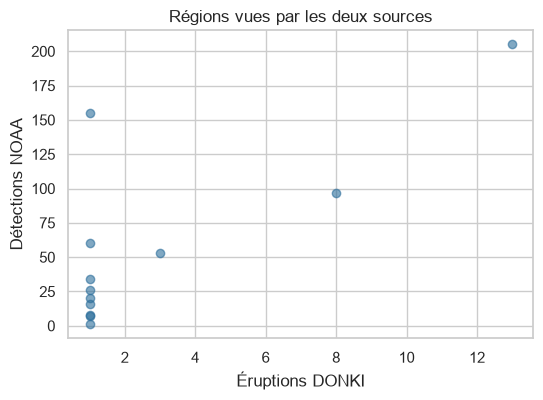

                      donki   noaa
active_region_number              
14513.0                13.0  205.0
14524.0                 8.0   97.0
14521.0                 3.0   53.0
14498.0                 1.0    1.0
14503.0                 1.0    8.0
14506.0                 1.0   60.0
14507.0                 1.0  155.0
14510.0                 1.0   34.0
14518.0                 1.0   16.0
14520.0                 1.0   20.0
14523.0                 1.0   26.0
14535.0                 1.0    7.0


In [20]:
plt.figure(figsize=(6, 4))
plt.scatter(communes["donki"], communes["noaa"], color=BLEU, alpha=0.6)
plt.title("Régions vues par les deux sources")
plt.xlabel("Éruptions DONKI")
plt.ylabel("Détections NOAA")
plt.show()

print(communes.sort_values("donki", ascending=False).to_string())

**Interprétation**

 Sur les 649 régions actives identifiées au total, seules 12 sont vues par les deux sources. À l'inverse, 621 régions sont présentes uniquement dans DONKI et 16 uniquement dans NOAA.

 Ce faible recouvrement s'explique principalement par la différence de profondeur temporelle entre les deux sources. DONKI couvre environ onze années d'historique, tandis que le flux NOAA disponible ne couvre qu'environ une trentaine de jours. Les régions présentes uniquement dans DONKI correspondent donc principalement à des périodes pour lesquelles aucune donnée NOAA n'est disponible. Le faible nombre de régions communes est ainsi cohérent avec la fenêtre temporelle limitée de NOAA.

 Les 12 régions communes appartiennent toutes à la période récente et présentent des numéros compris entre 14498 et 14535. Cela confirme que le croisement entre les deux sources fonctionne sur leur période de recouvrement et que les identifiants de régions permettent bien de faire le rapprochement entre les catalogues.
 
 Les 16 régions présentes uniquement dans NOAA sont également intéressantes. Elles montrent que NOAA peut détecter des régions qui ne sont pas nécessairement représentées dans DONKI. Cela est cohérent avec le biais de catalogage déjà identifié : DONKI ne constitue pas un inventaire exhaustif de toutes les activités solaires, notamment pour les événements de faible intensité. Pour confirmer précisément cette hypothèse, il faudrait examiner la classe des rayons X mesurée par NOAA pour ces régions, information non reprise dans le modèle de staging actuel.

 Le nuage de points montre enfin que le nombre de détections NOAA n'est pas proportionnel au nombre d'éruptions DONKI. Par exemple, la région 14507 compte seulement 1 éruption DONKI pour 155 détections NOAA, tandis que la région 14513 compte 13 éruptions pour 205 détections. Une même région peut donc générer de nombreuses détections NOAA pour relativement peu d'éruptions DONKI.

 Le nombre de détections NOAA ne peut donc pas être utilisé directement comme un indicateur du nombre d'éruptions. Les deux sources ont des grains d'observation différents : DONKI catalogue des événements solaires, tandis que NOAA fournit des détections instrumentales.

 Conséquence pour le Machine Learning : toute analyse combinant les deux sources doit être limitée à leur fenêtre temporelle commune et reposer sur un appariement explicite des événements. Les détections NOAA ne peuvent pas être ajoutées directement comme variable explicative au modèle entraîné sur les onze années de DONKI, car elles ne sont pas disponibles sur l'ensemble de cette période.



## 11. Synthèse et choix de la cible ML

In [21]:
retenues = flares[flares["classe_lettre"].isin(["M", "X"])]

resume = pd.Series({
    "Éruptions DONKI": len(flares),
    "Période couverte": f"{flares['annee'].min()} - {flares['annee'].max()}",
    "Régions actives": flares["active_region_number"].nunique(),
    "Détections NOAA": len(noaa),
    "Éruptions M et X": len(retenues),
    "Associées à un CME": int(retenues["declenche_cme"].sum()),
    "Taux de CME sur M-X": f"{retenues['declenche_cme'].mean() * 100:.1f} %",
})

print(resume.to_string())

Éruptions DONKI               3065
Période couverte       2015 - 2026
Régions actives                633
Détections NOAA               1366
Éruptions M et X              2453
Associées à un CME             665
Taux de CME sur M-X         27.1 %



### Ce que contiennent les données

L’analyse porte sur **3 065 éruptions solaires** cataloguées par DONKI entre 2015 et 2026, réparties sur **633 régions actives**. Elles sont complétées par des détections instrumentales NOAA disponibles sur une période récente d’environ trente jours.

### Les principaux biais identifiés

### Le seuil de catalogage.
L’analyse de la distribution des classes montre que DONKI ne constitue pas un inventaire exhaustif des éruptions solaires, notamment pour les faibles intensités. Le premier quartile de l’intensité se situe exactement à M1.0 et les éruptions M sont largement surreprésentées par rapport aux éruptions C. Les éruptions B et C présentes dans le catalogue ne peuvent donc pas être considérées comme représentatives de l’ensemble des éruptions de ces classes. Leur taux d’association apparent avec un CME est ainsi susceptible d’être influencé par le processus de sélection du catalogue.

### L’enrichissement a posteriori.
Le champ `linked_events`, utilisé pour identifier les CME associés, est renseigné après l’observation de l’événement. Un événement récent peut donc apparaître comme n’étant pas associé à un CME alors que le rapprochement n’a pas encore été effectué. La cible dépend ainsi en partie du processus d’enrichissement du catalogue.

### La fenêtre temporelle de NOAA.
Le flux NOAA disponible couvre environ trente jours, contre onze années pour DONKI. Sur les 649 régions identifiées au total, seules 12 sont communes aux deux sources. NOAA ne peut donc pas être utilisée directement pour entraîner un modèle sur l’ensemble de l’historique DONKI.

### Les pistes envisagées

J’ai considéré quatre cibles possibles :

1. **Association avec un CME** — classification binaire
2. **Classe de l’éruption (C/M/X)** — classification multi-classe
3. **Intensité de l’éruption** — régression
4. **Durée de l’éruption** — régression

Les pistes 2 et 3 cherchent principalement à caractériser l’intensité du rayonnement solaire, alors que la problématique porte sur l’anticipation d’événements susceptibles d’avoir des conséquences sur les infrastructures. L’intensité seule ne permet donc pas de caractériser directement ce risque : une éruption très intense n’est pas nécessairement associée à un CME, tandis qu’une éruption moins intense peut l’être.

La piste 4 est également moins adaptée à cette problématique. De plus, la durée complète de l’éruption n’est connue qu’une fois l’événement terminé.

### La cible retenue 

Je retiens donc la prédiction de l’association d’une éruption avec un CME, sous la forme d’une **classification binaire**.

Le modèle est entraîné uniquement sur les classes M et X, soit **2 453 éruptions**, dont **665 associées à un CME, soit 27,1 %**.

Ce choix permet de travailler sur le périmètre pour lequel le catalogue est le plus homogène et d’éviter que les taux très élevés observés pour les classes B et C, probablement influencés par le biais de sélection, ne soient directement utilisés pour construire la cible.

Ce scénario présente également un intérêt opérationnel : le rayonnement X d’une éruption atteint la Terre en quelques minutes, tandis qu’un CME met généralement de l’ordre de un à trois jours pour parcourir la distance Soleil-Terre. Prédire l’association avec un CME dès la fin de l’éruption peut donc fournir un délai supplémentaire pour anticiper les éventuelles perturbations liées à l’activité solaire, notamment pour les systèmes satellitaires et les réseaux électriques.

### Les variables retenues et écartées

Les variables explicatives sont sélectionnées selon une règle principale : elles doivent être disponibles au moment où la prédiction est réalisée.

Je retiens donc les caractéristiques disponibles à la fin de l’éruption : **classe et multiplicateur d’intensité, durée, temps de montée, position sur le disque solaire et historique de la région active**.

À l’inverse, `linked_events` est exclue puisqu’elle sert directement à construire la cible. L’utiliser comme variable explicative provoquerait une fuite de données.

L’année est également écartée : elle permet de décrire la période historique du catalogue, mais elle ne constitue pas une caractéristique intrinsèque d’une nouvelle éruption. Le numéro de région est lui aussi écarté, car il s’agit d’un identifiant et non d’une mesure physique.

### Le principal point de vigilance : le moment de la prédiction

Le choix des variables doit être cohérent avec le moment auquel le modèle est censé produire sa prédiction.

Ici, la prédiction intervient **à la fin de l’éruption**. La durée, l’heure de fin et le temps de montée peuvent donc être utilisés puisqu’ils sont alors connus.

En revanche, une variable renseignée uniquement après l’établissement du lien avec le CME ne doit pas être utilisée. Cette distinction permet d’éviter une fuite de données et de conserver un scénario de prédiction réaliste.

### Les limites

Plusieurs limites doivent être conservées à l’esprit :

* la cible dépend du rattachement des événements réalisé dans DONKI et peut donc comporter des labels incomplets ;
* le choix du périmètre M/X limite l’effet du biais de catalogage identifié, mais ne le supprime pas totalement ;
* l’hypothèse concernant les 13 régions présentes uniquement dans NOAA n’a pas pu être vérifiée avec le staging actuel ;
* NOAA ne peut pas être utilisée comme source d’entraînement sur l’ensemble de la période historique en raison de sa fenêtre temporelle limitée ;
* la validation du modèle devra tenir compte de l’ordre temporel des événements afin d’éviter qu’une information provenant du futur ne soit indirectement utilisée pour évaluer le modèle.

